Silakan upload file ZIP dataset retina...


Saving images_training.zip to images_training.zip
Jumlah gambar ditemukan: 20


Enhancing images: 100%|██████████| 20/20 [00:00<00:00, 31.89it/s]


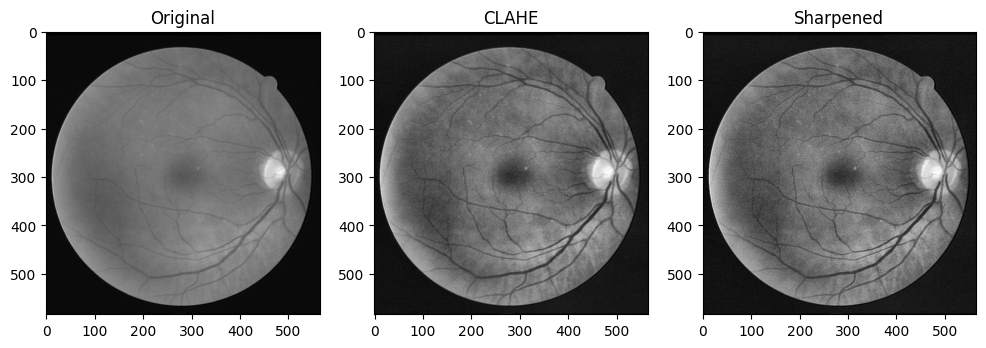

✅ Semua gambar retina sudah diproses.
📂 Folder hasil: enhanced_training_image
📦 File ZIP hasil: enhanced_training_image.zip


In [1]:
import cv2
import os
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
import zipfile
from tqdm import tqdm
import glob

# === Upload ZIP dataset ===
print("Silakan upload file ZIP dataset retina...")
uploaded = files.upload()
zip_path = next(iter(uploaded))  # ambil nama file pertama

# Ekstrak ke folder "training_image"
dataset_folder = "training_image"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_folder)

# Buat folder output
output_folder = "enhanced_training_image"
os.makedirs(output_folder, exist_ok=True)

# === Fungsi enhance khusus retina vessel ===
def enhance_retina(img_gray, clip_limit=3.0, grid_size=(8,8), alpha=1.5, beta=-0.5):
    """Enhance citra retina dengan CLAHE + Unsharp Masking"""
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid_size)
    clahe_img = clahe.apply(img_gray)

    # Gaussian blur untuk unsharp masking
    blur = cv2.GaussianBlur(clahe_img, (5,5), 0)
    sharpened = cv2.addWeighted(clahe_img, alpha, blur, beta, 0)

    return clahe_img, sharpened

# === Cari semua gambar dalam folder (termasuk subfolder) ===
valid_ext = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.tiff')
image_files = []
for ext in valid_ext:
    image_files.extend(glob.glob(os.path.join(dataset_folder, '**', ext), recursive=True))

print("Jumlah gambar ditemukan:", len(image_files))

# === Loop semua gambar ===
for path in tqdm(image_files, desc="Enhancing images"):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue  # skip kalau file tidak bisa dibaca

    clahe_img, sharpened = enhance_retina(img)

    # Ambil nama file tanpa folder
    filename = os.path.basename(path)

    # Simpan hasil
    cv2.imwrite(os.path.join(output_folder, f"clahe_{filename}"), clahe_img)
    cv2.imwrite(os.path.join(output_folder, f"sharpened_{filename}"), sharpened)

# === Tampilkan contoh hasil dari 1 gambar ===
if image_files:
    sample_path = image_files[0]
    sample_img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
    clahe_img, sharpened = enhance_retina(sample_img)

    plt.figure(figsize=(12,6))
    plt.subplot(1,3,1); plt.imshow(sample_img, cmap='gray'); plt.title("Original")
    plt.subplot(1,3,2); plt.imshow(clahe_img, cmap='gray'); plt.title("CLAHE")
    plt.subplot(1,3,3); plt.imshow(sharpened, cmap='gray'); plt.title("Sharpened")
    plt.show()

# === Auto ZIP hasil untuk download ===
zip_output = "enhanced_training_image.zip"
with zipfile.ZipFile(zip_output, 'w') as zipf:
    for file in os.listdir(output_folder):
        zipf.write(os.path.join(output_folder, file), arcname=file)

print(f"✅ Semua gambar retina sudah diproses.")
print(f"📂 Folder hasil: {output_folder}")
print(f"📦 File ZIP hasil: {zip_output}")
